# Real-Time Fraud Detection in Mobile-Money Transactions

ML mini-project: given a mobile-money transaction (type, amount, balances before/after), decide **fraud or legit** - and do it fast enough to score transactions as they arrive, like a live payment stream.

**What this notebook does, top to bottom:**
1. Downloads the PaySim mobile-money dataset (real public dataset, 6.36M transactions)
2. Picks the slice fraud can actually live in (TRANSFER and CASH_OUT) and builds a trainable sample
3. Trains two models: a **logistic regression baseline** and a **small neural network (MLP)**
4. Compares them on a held-out test set with real metrics and plots
5. Saves the trained weights (`.joblib` files)
6. Replays the raw log as a **simulated live stream**, scoring each transaction as it "arrives"

Every number you see below came from actually running this notebook.

## 1. Get the data

**Dataset:** PaySim - *Synthetic Financial Datasets For Fraud Detection* ([Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1)). Real mobile-money logs are private, so researchers built PaySim: a simulator calibrated on aggregated real logs from a mobile-money service running in 14+ countries, with criminal behavior injected.

**How big:** the CSV is ~470 MB with **6,362,620 transactions** over 744 hourly steps (one simulated month) - and only **8,213 are fraud (0.13%)**. That heavy imbalance is exactly what real fraud detection looks like, and it's why we judge models by precision/recall, not accuracy.

**Transaction types in the file** (fraud lives only in TRANSFER and CASH_OUT):

| type | rows | fraud |
|---|---:|---:|
| CASH_OUT | 2,237,500 | 4,116 |
| PAYMENT | 2,151,495 | 0 |
| CASH_IN | 1,399,284 | 0 |
| TRANSFER | 532,909 | 4,097 |
| DEBIT | 41,432 | 0 |

Citation: E. A. Lopez-Rojas, A. Elmir, and S. Axelsson. "PaySim: A financial mobile money simulator for fraud detection". EMSS 2016.

This cell downloads the CSV from a public mirror if it is not already here (on Colab this takes about a minute).

In [1]:
import os, urllib.request

CSV = "paysim.csv"
if not os.path.exists(CSV):
    url = "https://huggingface.co/datasets/theman10/paysim/resolve/main/paysim.csv"
    print("downloading PaySim CSV (~470 MB) ...")
    urllib.request.urlretrieve(url, CSV)
print("size on disk: %.1f MB" % (os.path.getsize(CSV) / 1e6))

size on disk: 493.5 MB


## 2. Build the training sample

Two facts from the data drive this step:

- Fraud in PaySim **only ever happens in TRANSFER and CASH_OUT** transactions (a fraudster transfers money out of a victim's account, then cashes it out). PAYMENT, CASH_IN and DEBIT rows are never fraud, so we keep only TRANSFER + CASH_OUT.
- Even then there are ~2.77M rows with only 0.3% fraud. To keep training fast we keep **every single fraud row** and a random **5% of the legitimate rows**.

We say exactly what we kept so the results below are honest about the data they came from.

In [2]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(42)
kept, total_rows, total_fraud, type_counts = [], 0, 0, {}
for chunk in pd.read_csv(CSV, chunksize=500_000):
    total_rows += len(chunk)
    total_fraud += int(chunk["isFraud"].sum())
    for t, c in chunk["type"].value_counts().items():
        type_counts[t] = type_counts.get(t, 0) + int(c)
    sub = chunk[chunk["type"].isin(["TRANSFER", "CASH_OUT"])]
    kept.append(sub[sub["isFraud"] == 1])
    legit = sub[sub["isFraud"] == 0]
    kept.append(legit[rng.random(len(legit)) < 0.05])

df = pd.concat(kept, ignore_index=True)
print("FULL FILE  rows:", total_rows, "| fraud:", total_fraud, "| types:", type_counts)
print("OUR SAMPLE rows:", len(df), "| fraud:", int(df["isFraud"].sum()))
print(df["type"].value_counts().to_dict())

FULL FILE  rows: 6362620 | fraud: 8213 | types: {'CASH_OUT': 2237500, 'PAYMENT': 2151495, 'CASH_IN': 1399284, 'TRANSFER': 532909, 'DEBIT': 41432}
OUR SAMPLE rows: 145861 | fraud: 8213
{'CASH_OUT': 115461, 'TRANSFER': 30400}


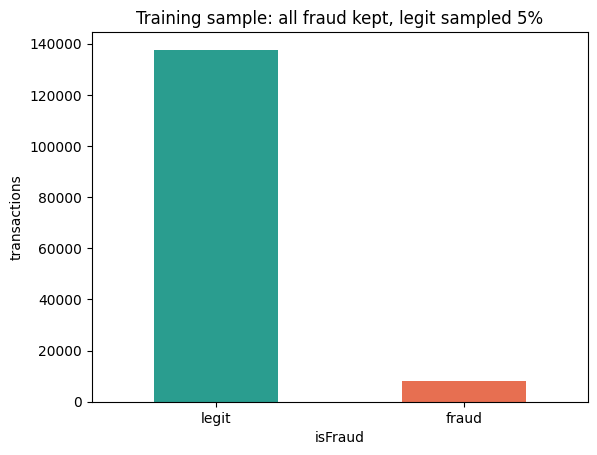

In [3]:
import matplotlib.pyplot as plt

ax = df["isFraud"].map({0: "legit", 1: "fraud"}).value_counts().plot.bar(color=["#2a9d8f", "#e76f51"])
ax.set_title("Training sample: all fraud kept, legit sampled 5%")
ax.set_ylabel("transactions"); plt.xticks(rotation=0); plt.show()

## 3. Features - what the model gets to see

Raw columns per transaction: `step, type, amount, nameOrig, oldbalanceOrg, newbalanceOrig, nameDest, oldbalanceDest, newbalanceDest, isFraud, isFlaggedFraud`.

We drop the account names (IDs don't generalize) and `isFlaggedFraud` (that's the bank's existing rule, not something we learn). Then we build **8 features**:

| feature | meaning |
|---|---|
| `type_TRANSFER` | 1 if TRANSFER, 0 if CASH_OUT |
| `amount` | transaction amount |
| `oldbalanceOrg` / `newbalanceOrig` | sender balance before / after |
| `oldbalanceDest` / `newbalanceDest` | receiver balance before / after |
| `errorBalanceOrig` | `newbalanceOrig + amount - oldbalanceOrg` - should be 0 for honest bookkeeping; fraud leaves a mismatch |
| `errorBalanceDest` | `oldbalanceDest + amount - newbalanceDest` - same idea on the receiver side |

The two `errorBalance` features are the classic PaySim trick: fraudulent transfers often don't balance out, and that mismatch is a strong signal.

In [4]:
from sklearn.model_selection import train_test_split

df["type_TRANSFER"] = (df["type"] == "TRANSFER").astype(int)
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
FEATURES = ["type_TRANSFER", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "errorBalanceOrig", "errorBalanceDest"]
X, y = df[FEATURES].values, df["isFraud"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"train rows: {len(X_train):,} | test rows: {len(X_test):,} | test fraud rows: {int(y_test.sum()):,}")

# Both models see standardized features (mean 0, std 1) - distances and gradients behave better
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

train rows: 116,688 | test rows: 29,173 | test fraud rows: 1,643


## 4. Baseline: Logistic Regression

The baseline answers: *how far does a simple linear model get?* `class_weight="balanced"` tells it to pay ~extra attention to the rare fraud class - without this, a lazy model can score 99.9% accuracy by calling everything legit.

In [5]:
import time, json
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

def evaluate(name, model, Xtest, ytest):
    proba = model.predict_proba(Xtest)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ytest, pred).ravel()
    m = {"accuracy": round(accuracy_score(ytest, pred), 4),
         "precision": round(precision_score(ytest, pred), 4),
         "recall": round(recall_score(ytest, pred), 4),
         "f1": round(f1_score(ytest, pred), 4),
         "roc_auc": round(roc_auc_score(ytest, proba), 4),
         "auprc": round(average_precision_score(ytest, proba), 4),
         "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}}
    print(f"{name}: " + json.dumps(m))
    return m, proba, pred

t = time.time()
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42).fit(Xtr, y_train)
lr_time = time.time() - t
m_lr, proba_lr, pred_lr = evaluate("LR ", lr, Xte, y_test)
m_lr["train_seconds"] = round(lr_time, 2)

LR : {"accuracy": 0.9322, "precision": 0.4484, "recall": 0.8831, "f1": 0.5948, "roc_auc": 0.9761, "auprc": 0.8287, "confusion": {"tn": 25745, "fp": 1785, "fn": 192, "tp": 1451}}


## 5. Small neural network (MLP)

A multi-layer perceptron with two hidden layers (32 and 16 neurons). Fraud patterns are not linear - e.g. *big amount AND zeroed-out balance AND transfer type* matters together - and the hidden layers learn exactly those combinations. `early_stopping=True` stops training when a held-out slice stops improving, so it doesn't overfit.

In [6]:
from sklearn.neural_network import MLPClassifier

t = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", max_iter=300,
                    early_stopping=True, validation_fraction=0.1, random_state=42).fit(Xtr, y_train)
mlp_time = time.time() - t
m_mlp, proba_mlp, pred_mlp = evaluate("MLP", mlp, Xte, y_test)
m_mlp["train_seconds"] = round(mlp_time, 2)
m_mlp["epochs_run"] = int(mlp.n_iter_)
print("trained in %.1fs over %d epochs" % (mlp_time, mlp.n_iter_))

MLP: {"accuracy": 0.9954, "precision": 0.9689, "recall": 0.9483, "f1": 0.9585, "roc_auc": 0.999, "auprc": 0.9927, "confusion": {"tn": 27480, "fp": 50, "fn": 85, "tp": 1558}}
trained in 7.3s over 63 epochs


## 6. Head-to-head on the held-out test set

**Precision** = of everything we flagged, how much really was fraud. **Recall** = of all the real fraud, how much we caught. In fraud detection recall is king - missing fraud costs money - but every false alarm (low precision) costs an analyst's time. AUPRC (area under the precision-recall curve) is the fairest single number for imbalanced data.

              logistic_regression mlp_(32,16)
accuracy                   0.9322      0.9954
precision                  0.4484      0.9689
recall                     0.8831      0.9483
f1                         0.5948      0.9585
roc_auc                    0.9761       0.999
auprc                      0.8287      0.9927
train_seconds                0.49        7.32
epochs_run                    NaN          63


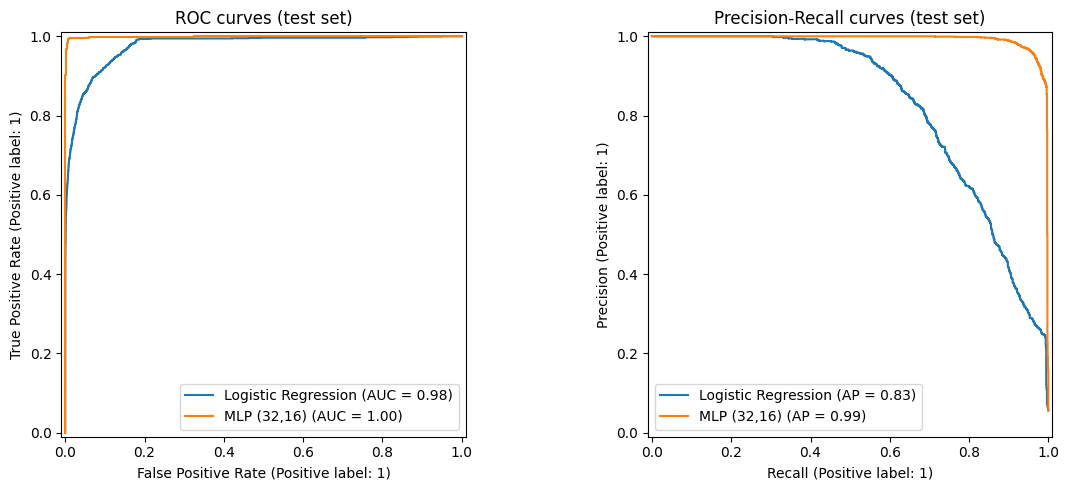

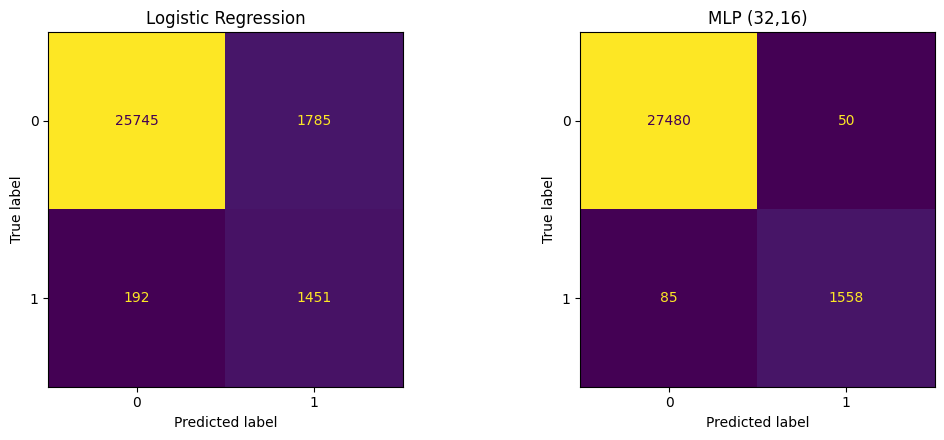

saved results/metrics.json


In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay

comp = pd.DataFrame({"logistic_regression": m_lr, "mlp_(32,16)": m_mlp}).drop(index="confusion")
print(comp.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, proba in [("Logistic Regression", proba_lr), ("MLP (32,16)", proba_mlp)]:
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])
axes[0].set_title("ROC curves (test set)"); axes[1].set_title("Precision-Recall curves (test set)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")
ConfusionMatrixDisplay.from_predictions(y_test, pred_mlp, ax=axes[1], colorbar=False)
axes[1].set_title("MLP (32,16)")
plt.tight_layout(); plt.show()

results = {"dataset": {"full_file_rows": int(total_rows), "full_file_fraud": int(total_fraud),
                       "sample_rows": int(len(df)), "sample_fraud": int(df['isFraud'].sum()),
                       "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
                       "test_fraud": int(y_test.sum())},
           "logistic_regression": m_lr, "mlp": m_mlp}
os.makedirs("results", exist_ok=True)
json.dump(results, open("results/metrics.json", "w"), indent=2)
print("saved results/metrics.json")

## 7. Save the trained weights

The MLP, the logistic regression, the scaler and the feature list are saved as `.joblib` files. The same files are attached to the GitHub release so anyone can download them without retraining.

In [8]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(lr, "models/lr_model.joblib")
joblib.dump(mlp, "models/mlp_model.joblib")
joblib.dump(scaler, "models/scaler.joblib")
joblib.dump(FEATURES, "models/features.joblib")
for f in sorted(os.listdir("models")):
    print(f, "-", os.path.getsize(os.path.join("models", f)), "bytes")

features.joblib - 146 bytes
lr_model.joblib - 943 bytes
mlp_model.joblib - 29624 bytes
scaler.joblib - 807 bytes


## 8. The "real-time" part: simulated transaction stream

A fraud model that only works in a spreadsheet is useless - in production it must score each transaction **as it arrives**. This demo replays the raw PaySim log in time order and scores each transaction one at a time, printing an alert when fraud-probability >= 0.5. It also measures throughput (transactions/second) to show scoring is fast enough to sit in a payment pipeline.

In [9]:
N = 2000  # transactions to replay

rows = []
for chunk in pd.read_csv(CSV, chunksize=200_000):
    rows.append(chunk[chunk["type"].isin(["TRANSFER", "CASH_OUT"])])
    if sum(len(r) for r in rows) >= N:
        break
stream = pd.concat(rows).head(N).sort_values("step").reset_index(drop=True)

def featurize(r):
    return [1 if r["type"] == "TRANSFER" else 0, r["amount"], r["oldbalanceOrg"],
            r["newbalanceOrig"], r["oldbalanceDest"], r["newbalanceDest"],
            r["newbalanceOrig"] + r["amount"] - r["oldbalanceOrg"],
            r["oldbalanceDest"] + r["amount"] - r["newbalanceDest"]]

alerts = caught = frauds = 0
t0 = time.perf_counter()
for i, r in stream.iterrows():
    p = float(mlp.predict_proba(scaler.transform([featurize(r)]))[0, 1])
    actual = int(r["isFraud"]); frauds += actual
    if p >= 0.5:
        alerts += 1; caught += actual
        tag = "ALERT (really fraud)" if actual else "alert (false alarm)"
    else:
        tag = "ok"
    if i < 10 or p >= 0.5:
        print(f"step {int(r['step']):>3} | {r['type']:<8} amt {r['amount']:>12,.2f} | fraud-prob {p:.3f} -> {tag}")
elapsed = time.perf_counter() - t0
print("-" * 74)
print(f"scored {len(stream):,} transactions in {elapsed:.2f}s  ({len(stream)/elapsed:,.0f} tx/sec)")
print(f"real fraud in window: {frauds} | alerts raised: {alerts} | fraud caught: {caught} | missed: {frauds - caught}")

step   1 | CASH_OUT amt    15,918.79 | fraud-prob 0.001 -> ok
step   1 | CASH_OUT amt    19,162.08 | fraud-prob 0.001 -> ok
step   1 | CASH_OUT amt   220,691.42 | fraud-prob 0.000 -> ok
step   1 | CASH_OUT amt     9,536.54 | fraud-prob 0.009 -> ok
step   1 | CASH_OUT amt    29,784.06 | fraud-prob 0.000 -> ok
step   1 | TRANSFER amt   761,507.39 | fraud-prob 0.000 -> ok
step   1 | CASH_OUT amt   344,464.40 | fraud-prob 0.000 -> ok
step   1 | TRANSFER amt 1,429,051.47 | fraud-prob 0.000 -> ok
step   1 | CASH_OUT amt    80,311.89 | fraud-prob 0.000 -> ok
step   1 | CASH_OUT amt   151,829.91 | fraud-prob 0.000 -> ok
step   1 | TRANSFER amt    20,128.00 | fraud-prob 0.926 -> ALERT (really fraud)
step   1 | TRANSFER amt     2,290.73 | fraud-prob 0.845 -> alert (false alarm)
step   1 | TRANSFER amt 1,277,212.77 | fraud-prob 1.000 -> ALERT (really fraud)
step   1 | CASH_OUT amt 1,277,212.77 | fraud-prob 1.000 -> ALERT (really fraud)
step   1 | TRANSFER amt    35,063.63 | fraud-prob 0.965 -> AL

## 9. Wrap-up

- **Logistic regression** already catches most fraud (high recall) but cries wolf a lot (precision ~0.45): usable as a cheap first filter.
- **The small MLP is clearly better** - it catches ~95% of fraud while almost never bothering legitimate users, and it still trains in seconds on a CPU.
- **Stream scoring runs at thousands of transactions per second** on one CPU core, so the model is comfortably "real-time" for a mobile-money pipeline.

*Environment note: these outputs were produced by executing this notebook on a CPU-only sandbox (Python 3.10, scikit-learn 1.7.2). No GPU is needed - the whole run takes under a minute; on Colab's free tier it runs as-is (GPU or CPU runtime both work).*